Labels {np.int64(0), np.int64(1)}
Noise points 0


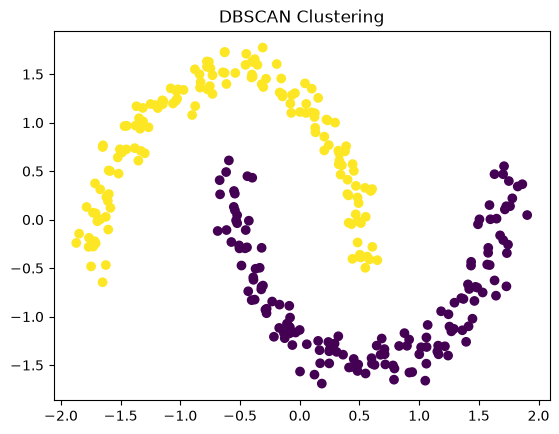

In [ ]:
# DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
# DBSCAN is a clustering model that groups closely packed data points
# into the same cluster and marks sparse/outlier points as noise (-1).
# It is useful when clusters have irregular shapes and do not need
# a fixed number of clusters in advance.

import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

X,_ = make_moons(
    n_samples= 300,
    noise=0.06,
    random_state= 42
)

X = StandardScaler().fit_transform(X)

model = DBSCAN(
    eps=0.25,
    min_samples=5
)

labels = model.fit_predict(X)

print("Labels", set(labels))
print("Noise points", sum(labels == -1))

plt.scatter(X[:,0], X[:,1], c=labels)

plt.title("DBSCAN Clustering")

plt.show()



Negative log-likelihood: 1.151013099072848
First five probability:
[[1.17343692e-31 1.00000000e+00 4.69659646e-29]
 [4.53427718e-30 1.00000000e+00 8.49633056e-29]
 [9.99993065e-01 1.06207809e-21 6.93506199e-06]
 [4.55118256e-10 2.25506562e-21 1.00000000e+00]
 [7.47259604e-35 1.00000000e+00 3.23233040e-35]]


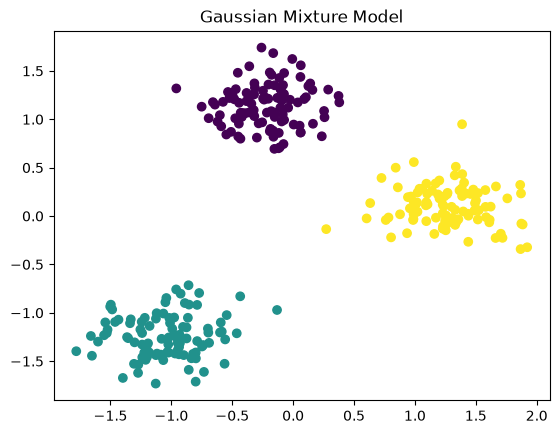

In [24]:
# Gaussian Mixture Model (GMM)
# GMM assumes that the data is generated from a mixture of several Gaussian distributions.
# It tries to find groups (clusters) by estimating the probability that each point belongs
# to each Gaussian component. Each point is assigned to the component with the highest probability.
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

X,_ = make_blobs(
    n_samples= 300,
    centers=3,
    cluster_std= 1.5,
    random_state= 42
)

X = StandardScaler().fit_transform(X)

model = GaussianMixture(
    n_components=3,
    covariance_type= "full",
    random_state= 42
)

model.fit(X)

labels = model.predict(X)
probabilities = model.predict_proba(X)

print("Negative log-likelihood:", -model.score(X))
print("First five probability:")
print(probabilities[:5])

plt.scatter(X[:,0], X[:,1], c=labels)

plt.title("Gaussian Mixture Model")

plt.show()

Original shape: (150, 4)
Reduced shape: (150, 2)
Variance explained: [0.72962445 0.22850762]
Total variance retained: 0.9581320720000166


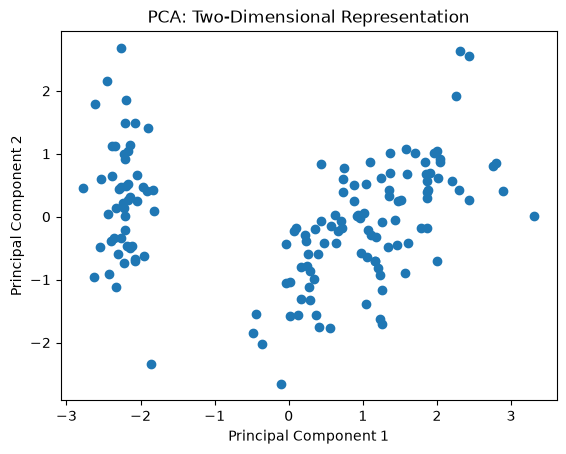

In [22]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = load_iris().data

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_scaled)

print("Original shape:", X.shape)
print("Reduced shape:", X_reduced.shape)

print(
    "Variance explained:",
    pca.explained_variance_ratio_
)
print(
    "Total variance retained:",
    pca.explained_variance_ratio_.sum()
)

plt.scatter(X_reduced[:,0], X_reduced[:,1])

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA: Two-Dimensional Representation")

plt.show()

In [27]:
# Autoencoder 
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

X = load_iris().data
X = StandardScaler().fit_transform(X)
X_tensor = torch.tensor(X, dtype=torch.float32)
loader = DataLoader(
    TensorDataset(X_tensor),
    batch_size= 16,
    shuffle= True
)

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(4,3),
            nn.ReLU(),
            nn.Linear(3,2)
        )

        self.decoder = nn.Sequential(
             nn.Linear(2,3),
            nn.ReLU(),
            nn.Linear(3,4)
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed

model = Autoencoder()
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

for epoch in range(100):
    total_loss =0

    for (batch,) in loader:
        optimizer.zero_grad()
        reconstructed = model(batch)
        loss = loss_fn(reconstructed, batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()*len(batch)

    if(epoch + 1) % 20 == 0:
         print(
            f"Epoch {epoch + 1},"
            f"Loss: {total_loss/len(X_tensor):.4f}"
        )

with torch.no_grad():
    latent_features = model.encoder(X_tensor)
    reconstructed = model(X_tensor)

print("Latent shape:", latent_features.shape)

print(
    "Final reconstructed MSE:",
    loss_fn(reconstructed, X_tensor).item()
)



Epoch 20,Loss: 0.7583
Epoch 40,Loss: 0.2646
Epoch 60,Loss: 0.1238
Epoch 80,Loss: 0.0775
Epoch 100,Loss: 0.0594
Latent shape: torch.Size([150, 2])
Final reconstructed MSE: 0.0588391050696373


In [37]:
import pandas as pd
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

transactions = [
    ["Bread", "Butter", "Milk"],
    ["Bread", "Butter"],
    ["Bread", "Milk"],
    ["Butter", "Milk"],
    ["Bread", "Butter", "Milk"],
    ["Bread", "Butter"],
]

items = sorted({
    item
    for transaction in transactions
    for item in transaction
})

df = pd.DataFrame([
    {
        item : item in transaction
        for item in items
    }
    for transaction in transactions
])

frequent_itemsets = apriori(
    df,
    min_support=0.3,
    use_colnames= True
)

print(frequent_itemsets)

    support                          itemsets
0  0.833333                frozenset({Bread})
1  0.833333               frozenset({Butter})
2  0.666667                 frozenset({Milk})
3  0.666667        frozenset({Bread, Butter})
4  0.500000          frozenset({Bread, Milk})
5  0.500000         frozenset({Milk, Butter})
6  0.333333  frozenset({Milk, Bread, Butter})


In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X , y = load_iris(return_X_y = True)

X_train, X_test , y_train , y_test = train_test_split(
    X , y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Training accuracy:", model.score(X_train, y_train))
print("Testing accuracy:", accuracy_score(y_test, y_pred))

Training accuracy: 1.0
Testing accuracy: 0.9


In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

X, y = load_iris(return_X_y= True)
model = RandomForestClassifier(random_state=42)

scores = cross_val_score(
    model, X, y,
    cv= 5,
    scoring="accuracy"
)

print("Scores for each fold:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Scores for each fold: [0.96666667 0.96666667 0.93333333 0.96666667 1.        ]
Mean accuracy: 0.9666666666666668
Standard deviation: 0.02108185106778919


In [ ]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

y_true = [100, 200, 300]
y_pred = [110, 190, 280]

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)

rmse = mse ** 0.5

r2 = r2_score(y_true, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 13.333333333333334
MSE: 200.0
RMSE: 14.142135623730951
R2: 0.97
